In [1]:
import torch
from torch import nn # nn: 包括torch的所有building blocks for 神经网络
import matplotlib.pyplot as plt 
torch.__version__

'2.12.0+cu126'

# 1. Data(preparing and loading)

## 用Linear Regression模拟

In [ ]:
# params
weight = 0.7
bias = 0.3

# 模拟一些数据
start = 0
end = 1
step = 0.02
# dim=1是因为一般 dim=0的位置表示的是样本数, dim=1的是特征数
X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias

In [5]:
print(f"X: {X.shape}\n{X[:5]}\n")
print(f"y: {y.shape}\n{y[:5]}\n")

X: torch.Size([50, 1])
tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800]])

y: torch.Size([50, 1])
tensor([[0.3000],
        [0.3140],
        [0.3280],
        [0.3420],
        [0.3560]])



## 划分数据集
一般来说, 有训练集、验证集(训练时评估效果)、测试集(最终评估效果)

其中验证集不是必须的

下面我们划分训练集和测试集

In [8]:
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]
len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

## 可视化数据

In [17]:
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):
    plt.figure(figsize=(10, 7))
    plt.scatter(train_data, train_labels, s=8, c="b", label="train_data")
    plt.scatter(test_data, test_labels, s=8, c="g", label="test_data")
    if predictions is not None:
        plt.scatter(test_data, predictions, s=8, c="r", label="predictions")
    plt.legend()

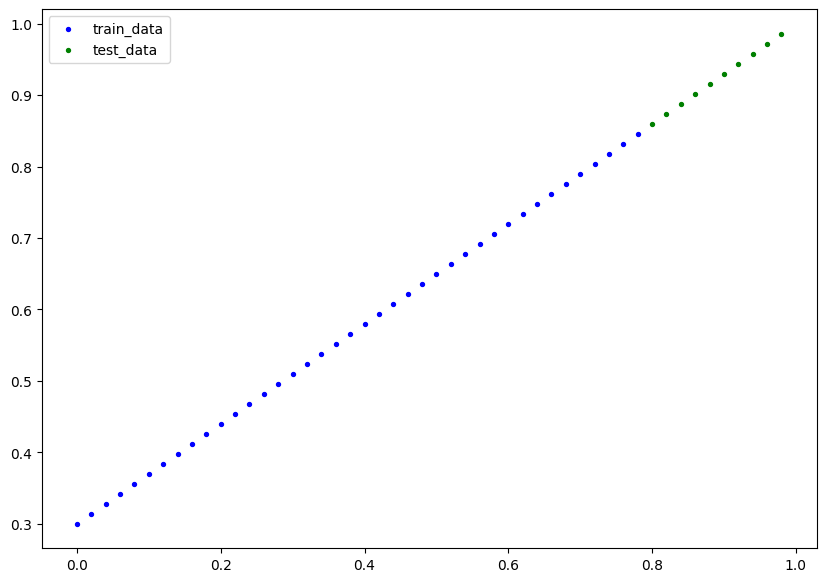

In [10]:
plot_predictions()

# 2. build model 构建模型

In [11]:
class LinearRegressionModel(nn.Module): # 所有神经网络类都必须继承nn.Module
    def __init__(self):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(1,
                                                  requires_grad=True,   # 默认True
                                                  dtype=torch.float32)) # 默认float32
        self.bias = nn.Parameter(torch.randn(1))
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.weight * x + self.bias
        

In [51]:
# 创建一个模型实例
RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)
model_0 = LinearRegressionModel()
# 查看模型参数
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [52]:
# 查看named parameters
model_0.state_dict()

OrderedDict([('weight', tensor([0.3367])), ('bias', tensor([0.1288]))])

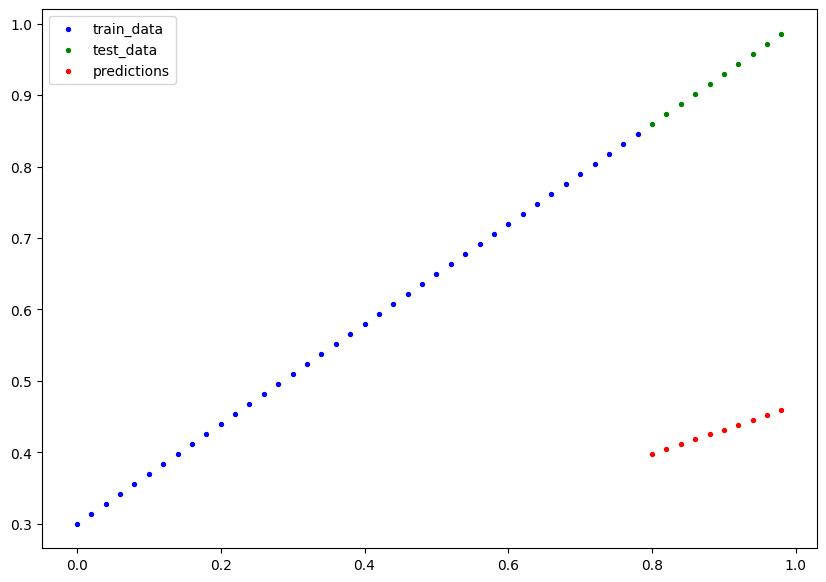

In [53]:
# 使用模型预测并可视化效果, use `torch.inference_mode`
# 关闭 gradient的track, 类似with torch.no_grad(): , 但是inference_mode更推荐使用
# 不记录gradient, 节省空间
with torch.inference_mode(): 
    y_preds = model_0(X_test)

plot_predictions(predictions=y_preds)

# 3. Train Model
What we need:
1. Loss Function
2. Optimizer(根据loss调整params的值)

In [54]:
# loss function
# 使用MAE
loss_fn = nn.L1Loss()

# Optimizer
# 使用 SGD 随机梯度下降
optimizer = torch.optim.SGD(params=model_0.parameters(), # 要optimize的参数
                            lr=0.01) # learning rate

In [55]:
loss_fn, optimizer

(L1Loss(),
 SGD (
 Parameter Group 0
     dampening: 0
     differentiable: False
     foreach: None
     fused: None
     lr: 0.01
     maximize: False
     momentum: 0
     nesterov: False
     weight_decay: 0
 ))

## Training Loop
0. 遍历所有 input
1. forward propagation(pass)
2. 计算 loss
3. optimizer zero_grad
4. loss back propagation
5. optimizer step

In [58]:
epoches = 200

# track values
epoch_count = []
loss_value = []
test_loss_value = []

for epoch in range(epoches):
    ## 进入 train mode, set require_grad = True
    model_0.train()
    
    # 1. forward propagation
    y_pred = model_0(X_train)
    
    # 2. caculate loss
    loss = loss_fn(y_pred, y_train)
    
    # 3. optimizer zero_grad
    # 清空模型参数上的梯度(param.grad), 避免上一次的back propagation的梯度被累加到这次
    optimizer.zero_grad()
    
    # 4. back propagation
    loss.backward()
    
    # 5. optimizer step
    optimizer.step()
    
    ## tesing
    # 关闭 evaluation/testing不需要的settings, 如固定 Dropout, BatchNorm层
    model_0.eval() 
    
    with torch.inference_mode():
        # 1. forward pass
        test_pred = model_0(X_test)    
        # 2. caculate loss
        test_loss = loss_fn(test_pred, y_test)
    
    if epoch % 10 == 0:
        epoch_count.append(epoch)
        loss_value.append(loss.detach().numpy())
        test_loss_value.append(test_loss.detach().numpy())
        print(f"epoch: {epoch}; loss: {loss}; test_loss: {test_loss}\nparams: {model_0.state_dict()}\n")

epoch: 0; loss: 0.28983935713768005; test_loss: 0.4541231691837311
params: OrderedDict({'weight': tensor([0.3484]), 'bias': tensor([0.1588])})

epoch: 10; loss: 0.1746293306350708; test_loss: 0.3194132149219513
params: OrderedDict({'weight': tensor([0.3874]), 'bias': tensor([0.2588])})

epoch: 20; loss: 0.07638873159885406; test_loss: 0.19773726165294647
params: OrderedDict({'weight': tensor([0.4258]), 'bias': tensor([0.3463])})

epoch: 30; loss: 0.05069301277399063; test_loss: 0.13647659122943878
params: OrderedDict({'weight': tensor([0.4564]), 'bias': tensor([0.3803])})

epoch: 40; loss: 0.04463795945048332; test_loss: 0.1100495308637619
params: OrderedDict({'weight': tensor([0.4788]), 'bias': tensor([0.3868])})

epoch: 50; loss: 0.04098063334822655; test_loss: 0.09699545800685883
params: OrderedDict({'weight': tensor([0.4974]), 'bias': tensor([0.3833])})

epoch: 60; loss: 0.0375034399330616; test_loss: 0.08666229248046875
params: OrderedDict({'weight': tensor([0.5152]), 'bias': tens

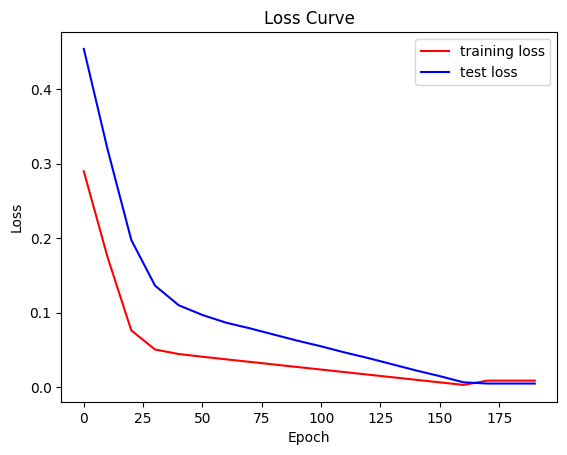

In [59]:
# Draw Loss Curve
plt.plot(epoch_count, loss_value, 'r', label="training loss")
plt.plot(epoch_count, test_loss_value, 'b', label="test loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.legend()

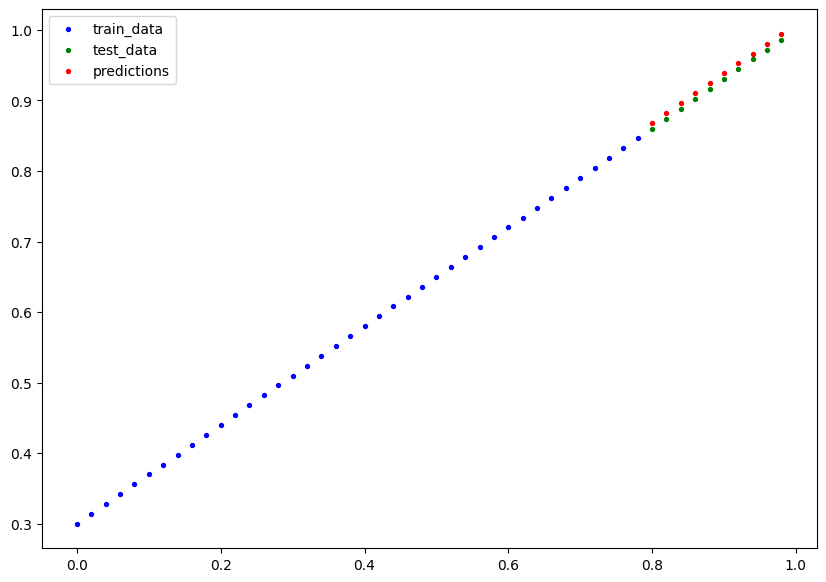

In [44]:
# 训练200次后, 预测效果明显提升:
plot_predictions(predictions=test_pred)

# Saving Model 保存模型

PyTorch的保存和读取模型模块有三个重要方法:
1. `torch.save()`
2. `torch.load()`
3. `torch.nn.Modules.load_state_dict()`

doc: https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html#saving-loading-model-for-inference

In [60]:
from pathlib import Path
MODEL_PATH = Path("model")
# 确保目录存在. 如果不存在, 则(递归)创建
MODEL_PATH.mkdir(parents=True, exist_ok=True)
MODEL_NAME = "01_pytorch_workflow_model.pt"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

print(f"saving model to: {MODEL_SAVE_PATH}")

# save model
torch.save(obj=model_0.state_dict(),
           f=MODEL_SAVE_PATH)

saving model to: model\01_pytorch_workflow_model.pt


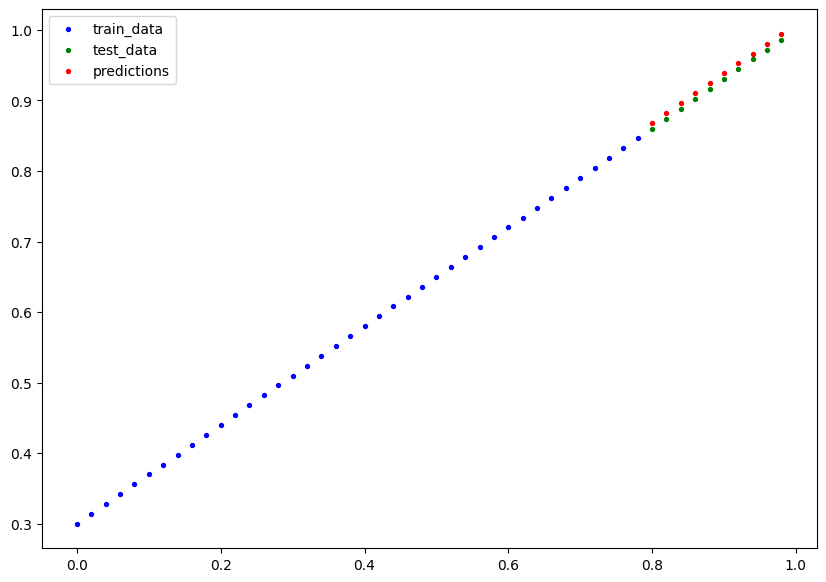

In [62]:
# load model(注意需要创建一个新的实例)
model_loaded = LinearRegressionModel()
model_loaded.load_state_dict(torch.load(f=MODEL_SAVE_PATH,
                                     weights_only=True))
# !不要忘记, load之后使用时需要调用.eval()方法
model_loaded.eval()
with torch.inference_mode():
    loaded_model_pred = model_loaded(X_test)

plot_predictions(predictions=loaded_model_pred)